# 06_new_experiments.ipynb — ทดลองวิธีใหม่เพิ่มเติม

โน้ตบุ๊กนี้ต่อยอดจาก `05_improved_pipeline4.ipynb` เพิ่ม 5 การทดลองที่ยังไม่เคยทำ:

1. **Imbalance techniques เพิ่มเติม**: RUS, BalancedRandomForest, EasyEnsemble, SMOTEENN, SMOTETomek (นอกเหนือจาก SMOTE/BorderlineSMOTE/ADASYN/class_weight เดิม)
2. **LACE-like composite score**: ฟีเจอร์ clinical risk score จาก time_in_hospital, admission_type, comorbidity, number_emergency
3. **Probability calibration**: เช็คว่า predicted probability สอดคล้องกับความเป็นจริงแค่ไหน (สำคัญกับ cost-based threshold ที่ทำไว้)
4. **Fairness/subgroup analysis**: performance แยกตาม race, gender, age — มุมที่ทั้งสองเปเปอร์อ้างอิงไม่มีใครทำ
5. **Permutation importance vs SHAP**: triangulate ผล interpretability

โน้ตบุ๊กนี้ **self-contained** — โหลดข้อมูลดิบและทำ cleaning/feature engineering ใหม่ทั้งหมด (เหมือนกับใน `05_improved_pipeline4.ipynb` ทุกขั้นตอน) เพื่อให้รันได้อิสระโดยไม่ต้องพึ่ง kernel state จากโน้ตบุ๊กก่อนหน้า

**ก่อนรัน**: ติดตั้ง package ที่ยังไม่มี
```
pip install imbalanced-learn shap xgboost
```


## 1. Imports

In [24]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, fbeta_score, f1_score,
    precision_score, recall_score, brier_score_loss, confusion_matrix,
    classification_report, precision_recall_curve,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

# --- imbalanced-learn: resamplers เดิม + ตัวใหม่ที่จะทดลองเพิ่ม ---
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler          # ใหม่
from imblearn.combine import SMOTEENN, SMOTETomek                # ใหม่
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier  # ใหม่

RANDOM_STATE = 42


## 2. Load & Clean Data
เหมือนกับ `05_improved_pipeline4.ipynb` เป๊ะ (ตัดผู้ป่วยที่เสียชีวิต/hospice, sort ตาม patient_nbr+encounter_id, reset_index)

In [25]:
RAW_PATH = "../data/diabetic_data.csv"  # แก้ path ตามที่เก็บไฟล์จริง

df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df.shape}")

df = df[df["gender"] != "Unknown/Invalid"]

death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]

df = df.sort_values(["patient_nbr", "encounter_id"])
df = df.reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")


Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)


### 2.1 แปลง Target Variable ทันที (ย้ายมาจากท้าย pipeline)

**สำคัญ**: ย้ายขั้นตอนนี้มาไว้ตั้งแต่ต้น (ก่อนฟีเจอร์เอนจิเนียริงทั้งหมด) เพราะเซลล์คำนวณ LACE score ด้านล่างต้องใช้ `df["readmitted"]` เป็นตัวเลขเพื่อเช็ค correlation — ถ้าปล่อยให้แปลงทีหลังเหมือน pipeline เดิม จะเจอ `ValueError: could not convert string to float: '<30'` เพราะตอนนั้นคอลัมน์ยังเป็น string (`'<30'`, `'>30'`, `'NO'`) อยู่

In [26]:
df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)
print(df["readmitted"].value_counts(normalize=True))


readmitted
0    0.886108
1    0.113892
Name: proportion, dtype: float64


## 3. Feature Engineering (เหมือนเดิม + ฟีเจอร์ LACE-like ใหม่)

In [27]:
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]

df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
df["change_flag"] = (df["change"] == "Ch").astype(int)
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)


In [28]:
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})
df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]


### 3.NEW — LACE-like composite score

อ้างอิงจาก Rahman et al. (2023, Diagnostics) ที่ใช้ LACE index (**L**ength of stay, **A**cuity of admission, **C**omorbidity, **E**mergency visits) เป็น top-2 predictor ของเขา เราไม่มี field ตรงๆ ของ CCI score แต่มีองค์ประกอบครบพอที่จะประมาณได้จาก dataset นี้เอง:

- **L**: `time_in_hospital` → แปลงตามตาราง LACE ต้นฉบับ (1,2,3,4-6,7-13,>=14 วัน → 1,2,3,4,5,7 คะแนน)
- **A**: `admission_type_id` เป็น Emergency/Urgent/Trauma (id 1,2,7) → 3 คะแนน มิฉะนั้น 0
- **C**: ใช้ `comorbidity_count` ที่ engineer ไว้แล้วแทน CCI score จริง (capped ที่ 4)
- **E**: `number_emergency` (capped ที่ 4)

**ข้อจำกัดที่ต้องระวัง**: นี่เป็น LACE ที่ "ประมาณ" จาก field ที่มีอยู่ ไม่ใช่ CCI score ที่คำนวณจาก ICD-9 diagnosis codes อย่างเป็นทางการ (Charlson Comorbidity Index จริงต้องใช้ weighted comorbidity list) — ควรระบุข้อจำกัดนี้ตรงๆ ใน methodology ถ้าเอาไปเขียนรายงาน

In [29]:
def lace_L(days):
    if days <= 1:
        return 1
    elif days == 2:
        return 2
    elif days == 3:
        return 3
    elif 4 <= days <= 6:
        return 4
    elif 7 <= days <= 13:
        return 5
    else:
        return 7

# admission_type_id: 1=Emergency, 2=Urgent, 7=Trauma Center -> ถือเป็น acute admission
emergency_admission_types = {1, 2, 7}
def lace_A(admission_type_id):
    return 3 if admission_type_id in emergency_admission_types else 0

def lace_C(comorbidity_count):
    return min(comorbidity_count, 4)

def lace_E(number_emergency):
    return min(number_emergency, 4)

df["lace_L"] = df["time_in_hospital"].apply(lace_L)
df["lace_A"] = df["admission_type_id"].apply(lace_A)
df["lace_C"] = df["comorbidity_count"].apply(lace_C)
df["lace_E"] = df["number_emergency"].apply(lace_E)
df["lace_score"] = df["lace_L"] + df["lace_A"] + df["lace_C"] + df["lace_E"]

print(df["lace_score"].describe())
print("\nCorrelation lace_score vs readmitted:", df["lace_score"].corr(df["readmitted"]))
print("\nMean lace_score by class:")
print(df.groupby("readmitted")["lace_score"].mean())


count    99340.000000
mean         7.903000
std          2.166801
min          2.000000
25%          7.000000
50%          8.000000
75%         10.000000
max         17.000000
Name: lace_score, dtype: float64

Correlation lace_score vs readmitted: 0.06607847748044449

Mean lace_score by class:
readmitted
0    7.851669
1    8.302369
Name: lace_score, dtype: float64


### 3.5 ลด/ตัดคอลัมน์ + จัดกลุ่ม medical_specialty (เหมือนเดิม)

In [30]:
drop_cols = ["weight", "payer_code", "encounter_id"]
df.drop(columns=drop_cols, inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(
    df["medical_specialty"].isin(top_specialties), "Other"
)

df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Dropping constant columns: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)


Dropping constant columns: ['examide', 'citoglipton']


## 4. Encode + Train/Test Split (GroupShuffleSplit ตาม patient_nbr — เหมือนเดิม)

In [31]:
TARGET_COL = "readmitted"
GROUP_COL = "patient_nbr"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

feature_cols = [c for c in X.columns if c != GROUP_COL]
categorical_cols = [c for c in feature_cols if pd.api.types.is_string_dtype(X[c])]
if "age" in categorical_cols:
    categorical_cols.remove("age")
X = X.drop(columns=["age"])
numeric_cols = [c for c in feature_cols if c not in categorical_cols and c != "age"]

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

# เก็บ demographic columns ของ test set ไว้ต่างหาก (ยังไม่ encode) ไว้ใช้ตอน fairness analysis ข้อ 8
demographic_cols_raw = df[["race", "gender", "age"]].copy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=df[GROUP_COL]))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
demo_test = demographic_cols_raw.iloc[test_idx].reset_index(drop=True)

X_train.drop(columns=[GROUP_COL], inplace=True)
X_test.drop(columns=[GROUP_COL], inplace=True)

overlap = set(df.iloc[train_idx][GROUP_COL]) & set(df.iloc[test_idx][GROUP_COL])
print(f"Patient overlap (ต้องเป็น 0): {len(overlap)}")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train target rate: {y_train.mean():.4f}, Test target rate: {y_test.mean():.4f}")


Patient overlap (ต้องเป็น 0): 0
Train: (79567, 59), Test: (19773, 59)
Train target rate: 0.1140, Test target rate: 0.1135


## 5. Experiment A — เปรียบเทียบเทคนิคจัดการ Imbalance เพิ่มเติม

นอกเหนือจาก SMOTE / BorderlineSMOTE / ADASYN / class_weight="balanced" ที่ทำไปแล้วใน `05_improved_pipeline4.ipynb` เพิ่มวิธีใหม่ 5 วิธี:

- **RandomUnderSampler (RUS)**: ตามเปเปอร์ Lu & Uddin (2022) — ตัด majority class ทิ้งแบบสุ่ม
- **SMOTEENN / SMOTETomek**: ผสม oversampling กับการลบ noisy/borderline samples ออก
- **BalancedRandomForestClassifier**: bootstrap แต่ละ tree แบบ balanced จากในตัว ไม่ต้อง resample แยก
- **EasyEnsembleClassifier**: ensemble ของ AdaBoost หลายตัว แต่ละตัวเทรนบน balanced subsample (ออกแบบมาสำหรับ imbalance โดยเฉพาะ)

วัดด้วย **PR-AUC** (average_precision) เหมือนเดิม เพื่อให้เทียบกับผลเก่าได้ตรงกัน

In [32]:
resampling_options_v2 = {
    "RUS": ImbPipeline([
        ("resample", RandomUnderSampler(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "SMOTEENN": ImbPipeline([
        ("resample", SMOTEENN(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "SMOTETomek": ImbPipeline([
        ("resample", SMOTETomek(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "BalancedRandomForest (built-in)": BalancedRandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=1,
        sampling_strategy="all", replacement=True, bootstrap=False,
    ),
    "EasyEnsemble": EasyEnsembleClassifier(
        n_estimators=10, random_state=RANDOM_STATE, n_jobs=1,
    ),
}

# หมายเหตุ (Windows): ตั้งใจใช้ cv.split() วนลูปเอง + n_jobs=1 ทุกจุด แทน cross_val_score(n_jobs=-1)
# เพราะ cross_val_score(n_jobs=-1) จะสร้าง worker process ขนานกันหลายตัวพร้อมกัน (nested
# parallelism กับ resampler/estimator ข้างในที่ก็พยายาม spawn process ของตัวเอง) ทำให้ Windows
# ขึ้น OSError: [WinError 1450] Insufficient system resources exist to complete the requested service
# (สร้าง process/handle ไม่ทันเพราะขอพร้อมกันเยอะเกินไป) วิธีแก้คือรันแบบ sequential แทน
# ช้าลงหน่อยแต่เสถียร ถ้าเครื่องเป็น Mac/Linux หรืออยากลองเร่งความเร็ว เปลี่ยนกลับไปใช้
# cross_val_score(pipe, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1) ได้
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
results_v2 = {}
for name, pipe in resampling_options_v2.items():
    fold_scores = []
    for train_i, val_i in cv.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_i], X_train.iloc[val_i]
        y_tr, y_val = y_train.iloc[train_i], y_train.iloc[val_i]
        pipe.fit(X_tr, y_tr)
        proba = pipe.predict_proba(X_val)[:, 1]
        fold_scores.append(average_precision_score(y_val, proba))
    fold_scores = np.array(fold_scores)
    results_v2[name] = fold_scores.mean()
    print(f"{name:38s} PR-AUC (CV mean): {fold_scores.mean():.4f} (+/- {fold_scores.std():.4f})")

print("\n>>> เทียบกับผลเดิมจาก 05_improved_pipeline4.ipynb (SMOTE/BorderlineSMOTE/ADASYN/class_weight)")
print(">>> ให้เอาตัวเลขจากทั้งสองรอบมาต่อกันเป็นตารางเดียวใน writeup")
best_new_technique = max(results_v2, key=results_v2.get)
print(f"\n>>> วิธีที่ดีที่สุดในกลุ่มใหม่นี้: {best_new_technique} (PR-AUC={results_v2[best_new_technique]:.4f})")


RUS                                    PR-AUC (CV mean): 0.2044 (+/- 0.0081)
SMOTEENN                               PR-AUC (CV mean): 0.1600 (+/- 0.0014)
SMOTETomek                             PR-AUC (CV mean): 0.1471 (+/- 0.0002)
BalancedRandomForest (built-in)        PR-AUC (CV mean): 0.2079 (+/- 0.0072)
EasyEnsemble                           PR-AUC (CV mean): 0.1961 (+/- 0.0027)

>>> เทียบกับผลเดิมจาก 05_improved_pipeline4.ipynb (SMOTE/BorderlineSMOTE/ADASYN/class_weight)
>>> ให้เอาตัวเลขจากทั้งสองรอบมาต่อกันเป็นตารางเดียวใน writeup

>>> วิธีที่ดีที่สุดในกลุ่มใหม่นี้: BalancedRandomForest (built-in) (PR-AUC=0.2079)


## 6. Experiment B — LACE score มี predictive power จริงหรือไม่

เทียบ PR-AUC ของโมเดล **ที่มี** vs **ไม่มี** `lace_score` (และองค์ประกอบย่อย) ใน feature set แบบ controlled — ถ้า PR-AUC ไม่ต่างกันเลย แปลว่า information ใน LACE score ถูก capture ไปแล้วโดย raw features (time_in_hospital, comorbidity_count, number_emergency ฯลฯ) ที่มีอยู่แล้ว

In [33]:
lace_cols = ["lace_L", "lace_A", "lace_C", "lace_E", "lace_score"]

X_train_with_lace = X_train.copy()
X_test_with_lace = X_test.copy()

X_train_without_lace = X_train.drop(columns=lace_cols)
X_test_without_lace = X_test.drop(columns=lace_cols)

rf_baseline = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                       random_state=RANDOM_STATE, n_jobs=-1)

rf_baseline.fit(X_train_without_lace, y_train)
proba_without = rf_baseline.predict_proba(X_test_without_lace)[:, 1]
pr_auc_without = average_precision_score(y_test, proba_without)

rf_baseline2 = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                        random_state=RANDOM_STATE, n_jobs=-1)
rf_baseline2.fit(X_train_with_lace, y_train)
proba_with = rf_baseline2.predict_proba(X_test_with_lace)[:, 1]
pr_auc_with = average_precision_score(y_test, proba_with)

print(f"PR-AUC ไม่มี lace features : {pr_auc_without:.4f}")
print(f"PR-AUC มี lace features    : {pr_auc_with:.4f}")
print(f"ส่วนต่าง                   : {pr_auc_with - pr_auc_without:+.4f}")

# permutation importance เฉพาะ lace_score เทียบกับฟีเจอร์อื่น
perm_lace = permutation_importance(rf_baseline2, X_test_with_lace, y_test, scoring="average_precision",
                                     n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp_lace = pd.Series(perm_lace.importances_mean, index=X_test_with_lace.columns).sort_values(ascending=False)
lace_rank = list(perm_imp_lace.index).index("lace_score") + 1
print(f"\nอันดับ lace_score ใน permutation importance: {lace_rank} จากทั้งหมด {len(perm_imp_lace)} ฟีเจอร์")
print("\nTop 10 permutation importance:")
print(perm_imp_lace.head(10))


PR-AUC ไม่มี lace features : 0.2140
PR-AUC มี lace features    : 0.2153
ส่วนต่าง                   : +0.0013

อันดับ lace_score ใน permutation importance: 14 จากทั้งหมด 59 ฟีเจอร์

Top 10 permutation importance:
number_inpatient             0.024184
total_prior_visits           0.013595
hospital_stay_x_inpatient    0.012489
discharge_disposition_id     0.011700
had_prior_inpatient          0.005326
age_ord                      0.003993
visit_number                 0.003967
num_procedures               0.002386
diag_1                       0.002065
num_medications              0.002006
dtype: float64


## 7. Experiment C — Probability Calibration

โมเดลที่เทรนด้วยเทคนิค imbalance (โดยเฉพาะ oversampling) มักให้ probability ที่ **miscalibrated** — เช่น โมเดลบอกว่า 70% เสี่ยง แต่จริงๆ กลุ่มนั้นมีคน readmit แค่ 40% การใช้ cost-based threshold (ที่ทำไว้ในขั้นตอน 10 ของ pipeline หลัก) จะแม่นก็ต่อเมื่อ probability สะท้อนความจริง ไม่งั้น threshold ที่ "optimal" อาจไม่ optimal จริงเมื่อเอาไปใช้กับข้อมูลใหม่

เทียบ **ก่อน** และ **หลัง** calibration ด้วย `CalibratedClassifierCV` (isotonic regression)

PR-AUC   ก่อน calibrate: 0.2153
PR-AUC   หลัง calibrate: 0.2127
Brier    ก่อน calibrate: 0.2026  (ยิ่งต่ำยิ่งดี)
Brier    หลัง calibrate: 0.0966


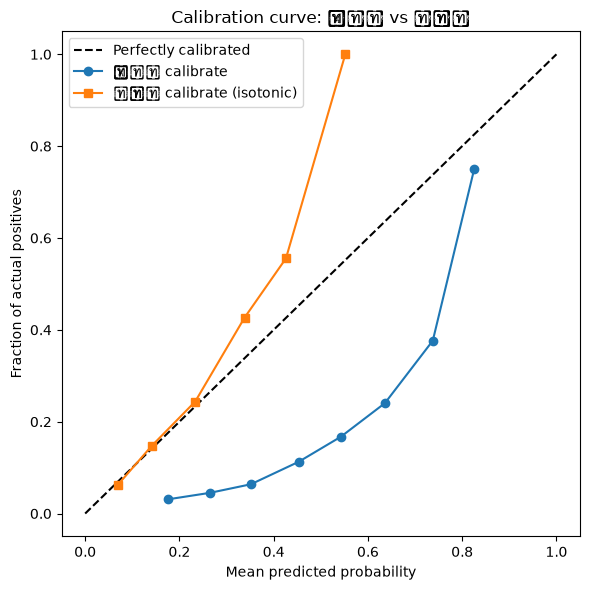


>>> ถ้า Brier score หลัง calibrate ต่ำลงชัดเจน แปลว่าควรใช้ calibrated_model
>>> แทน rf_for_calibration ตอนคำนวณ cost-based threshold ในขั้นตอน 10 ของ pipeline หลัก


In [34]:
rf_for_calibration = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                              random_state=RANDOM_STATE, n_jobs=-1)
rf_for_calibration.fit(X_train, y_train)
proba_raw = rf_for_calibration.predict_proba(X_test)[:, 1]

calibrated_model = CalibratedClassifierCV(rf_for_calibration, method="isotonic", cv=3)
calibrated_model.fit(X_train, y_train)
proba_calibrated = calibrated_model.predict_proba(X_test)[:, 1]

print(f"PR-AUC   ก่อน calibrate: {average_precision_score(y_test, proba_raw):.4f}")
print(f"PR-AUC   หลัง calibrate: {average_precision_score(y_test, proba_calibrated):.4f}")
print(f"Brier    ก่อน calibrate: {brier_score_loss(y_test, proba_raw):.4f}  (ยิ่งต่ำยิ่งดี)")
print(f"Brier    หลัง calibrate: {brier_score_loss(y_test, proba_calibrated):.4f}")

frac_pos_raw, mean_pred_raw = calibration_curve(y_test, proba_raw, n_bins=10)
frac_pos_cal, mean_pred_cal = calibration_curve(y_test, proba_calibrated, n_bins=10)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.plot(mean_pred_raw, frac_pos_raw, "o-", label="ก่อน calibrate")
plt.plot(mean_pred_cal, frac_pos_cal, "s-", label="หลัง calibrate (isotonic)")
plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of actual positives")
plt.title("Calibration curve: ก่อน vs หลัง")
plt.legend()
plt.tight_layout()
plt.show()

print("\n>>> ถ้า Brier score หลัง calibrate ต่ำลงชัดเจน แปลว่าควรใช้ calibrated_model")
print(">>> แทน rf_for_calibration ตอนคำนวณ cost-based threshold ในขั้นตอน 10 ของ pipeline หลัก")


## 8. Experiment D — Fairness / Subgroup Analysis

ประเมิน performance แยกตาม **race**, **gender**, **age** บน test set — ตรวจว่าโมเดลทำนายแม่นเท่ากันในทุกกลุ่มประชากรไหม (มุมที่ทั้งสองเปเปอร์อ้างอิงไม่มีใครทำ) กลุ่มที่มีขนาดเล็กเกินไป (<30 คน) จะถูกข้ามเพราะ metric ไม่เสถียร

In [35]:
def subgroup_report(y_true, y_proba, group_values, group_name, threshold=0.5, min_group_size=30):
    print(f"\n--- Subgroup performance by {group_name} ---")
    results = []
    for g in sorted(set(group_values)):
        mask = (group_values == g)
        if mask.sum() < min_group_size:
            continue
        y_t = y_true[mask]
        y_p = y_proba[mask]
        if y_t.nunique() < 2:
            continue
        y_pred = (y_p >= threshold).astype(int)
        results.append({
            "group": g,
            "n": int(mask.sum()),
            "base_rate": round(y_t.mean(), 4),
            "PR_AUC": round(average_precision_score(y_t, y_p), 4),
            "ROC_AUC": round(roc_auc_score(y_t, y_p), 4),
            "F2": round(fbeta_score(y_t, y_pred, beta=2, zero_division=0), 4),
            "Recall": round(recall_score(y_t, y_pred, zero_division=0), 4),
        })
    res_df = pd.DataFrame(results).sort_values("n", ascending=False)
    print(res_df.to_string(index=False))
    return res_df

y_test_reset = y_test.reset_index(drop=True)
# ใช้ proba_raw จาก Experiment C (โมเดล RF ตัวเดียวกัน) เพื่อความสอดคล้อง
race_report = subgroup_report(y_test_reset, proba_raw, demo_test["race"], "race")
gender_report = subgroup_report(y_test_reset, proba_raw, demo_test["gender"], "gender")
age_report = subgroup_report(y_test_reset, proba_raw, demo_test["age"], "age")

print("\n>>> ถ้ากลุ่มไหนมี PR-AUC/ROC-AUC ต่ำกว่ากลุ่มอื่นอย่างมีนัยสำคัญ ควรพูดถึงใน discussion")
print(">>> ว่าโมเดลอาจมี disparate performance และเสนอแนะการ validate เพิ่มเติมในกลุ่มนั้น")



--- Subgroup performance by race ---
          group     n  base_rate  PR_AUC  ROC_AUC     F2  Recall
      Caucasian 14813     0.1172  0.2257   0.6699 0.3868  0.5115
AfricanAmerican  3697     0.1079  0.1846   0.6597 0.3666  0.5013
        Missing   447     0.0716  0.1275   0.6305 0.2228  0.2812
       Hispanic   398     0.0905  0.2556   0.7673 0.3750  0.5000
          Other   302     0.1026  0.2248   0.6735 0.3143  0.3548
          Asian   116     0.0862  0.1798   0.6887 0.3788  0.5000

--- Subgroup performance by gender ---
 group     n  base_rate  PR_AUC  ROC_AUC     F2  Recall
Female 10726     0.1145  0.2234   0.6814 0.3970  0.5391
  Male  9047     0.1123  0.2072   0.6576 0.3579  0.4616

--- Subgroup performance by age ---
   group    n  base_rate  PR_AUC  ROC_AUC     F2  Recall
 [70-80) 4921     0.1130  0.1878   0.6546 0.3763  0.5324
 [60-70) 4356     0.1157  0.2067   0.6561 0.3576  0.4563
 [50-60) 3467     0.1087  0.2806   0.7201 0.4123  0.5013
 [80-90) 3284     0.1215  0.1735  

## 9. Experiment E — Permutation Importance vs SHAP

`05_improved_pipeline4.ipynb` มี SHAP อยู่แล้ว (ขั้นตอน 11) ที่นี่เพิ่ม **permutation importance** เป็นวิธีที่สอง (model-agnostic เหมือนกัน แต่คำนวณต่างกัน — SHAP ใช้ game theory, permutation importance ใช้ performance drop หลัง shuffle ค่าฟีเจอร์) เพื่อ triangulate ว่าฟีเจอร์ที่สำคัญตรงกันทั้งสองวิธีไหม

In [36]:
rf_final = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced",
                                    random_state=RANDOM_STATE, n_jobs=-1)
rf_final.fit(X_train, y_train)

perm_final = permutation_importance(rf_final, X_test, y_test, scoring="average_precision",
                                      n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp_final = pd.Series(perm_final.importances_mean, index=X_test.columns).sort_values(ascending=False)

print("Top 15 จาก Permutation Importance (PR-AUC drop):")
print(perm_imp_final.head(15))

print("\n>>> เอา list นี้ไปเทียบกับ mean_abs_shap จากขั้นตอนที่ 11 ของ 05_improved_pipeline4.ipynb")
print(">>> ถ้า top features ตรงกัน (เช่น number_inpatient, discharge_disposition_id) = ผล interpretability robust")
print(">>> ถ้าไม่ตรงกัน ต้องพิจารณาเพิ่มเติมว่าเป็นเพราะ multicollinearity หรือวิธีวัดต่างกัน")


Top 15 จาก Permutation Importance (PR-AUC drop):
number_inpatient             0.023542
total_prior_visits           0.013281
hospital_stay_x_inpatient    0.012298
discharge_disposition_id     0.011934
had_prior_inpatient          0.004609
age_ord                      0.003824
visit_number                 0.003537
num_procedures               0.002505
diag_1                       0.002083
metformin                    0.001899
num_meds_active              0.001782
num_medications              0.001767
A1Cresult                    0.001443
time_in_hospital             0.001346
medical_specialty            0.001193
dtype: float64

>>> เอา list นี้ไปเทียบกับ mean_abs_shap จากขั้นตอนที่ 11 ของ 05_improved_pipeline4.ipynb
>>> ถ้า top features ตรงกัน (เช่น number_inpatient, discharge_disposition_id) = ผล interpretability robust
>>> ถ้าไม่ตรงกัน ต้องพิจารณาเพิ่มเติมว่าเป็นเพราะ multicollinearity หรือวิธีวัดต่างกัน


## 10. Classification Report + Confusion Matrix (Visualization)

ใช้ `calibrated_model` (จาก Experiment C) เป็นโมเดลสรุปผลสุดท้าย เทียบ 2 threshold:
- **0.5** (ค่า default)
- **F2-optimal** (เน้น recall มากกว่า precision เพราะพลาดเคส readmit จริงมี cost สูงกว่าการแจ้งเตือนเกิน — ตามหลักการเดียวกับที่ใช้ในขั้นตอน 10 ของ `05_improved_pipeline4.ipynb`)

แสดงทั้ง confusion matrix แบบตัวเลขจริงและแบบ normalize เป็น % ต่อแถว (actual class) เพื่อดูง่ายว่าโมเดลพลาดกลุ่มไหนมากกว่ากัน

F2-optimal threshold: 0.0883

Threshold = 0.5 (threshold=0.500)
                    precision    recall  f1-score   support

Not readmitted (0)     0.8866    1.0000    0.9399     17529
    Readmitted (1)     1.0000    0.0004    0.0009      2244

          accuracy                         0.8866     19773
         macro avg     0.9433    0.5002    0.4704     19773
      weighted avg     0.8994    0.8866    0.8333     19773


Threshold = 0.088 (F2-optimal) (threshold=0.088)
                    precision    recall  f1-score   support

Not readmitted (0)     0.9433    0.4378    0.5981     17529
    Readmitted (1)     0.1532    0.7946    0.2569      2244

          accuracy                         0.4783     19773
         macro avg     0.5483    0.6162    0.4275     19773
      weighted avg     0.8537    0.4783    0.5594     19773



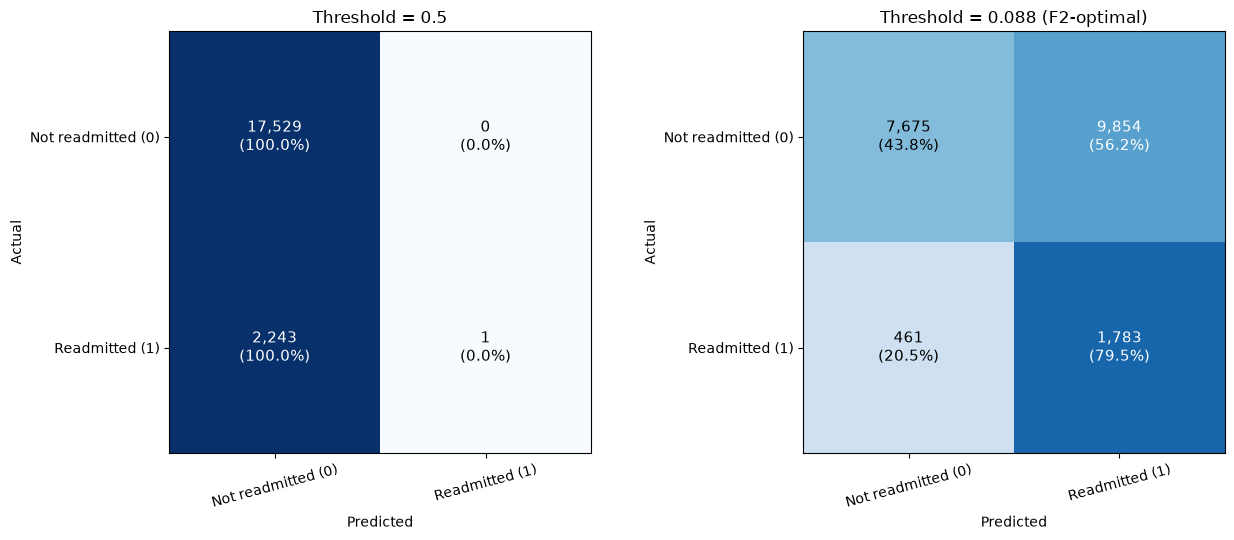


>>> ที่ threshold=0.5 โมเดลมักจะ recall ต่ำมาก (ทายกลุ่ม readmitted ว่าไม่ readmit เกือบหมด)
>>> เพราะ dataset นี้ imbalance สูง (~11%) — F2-optimal threshold ควรจับ readmitted ได้มากขึ้น
>>> แลกกับ false positive ที่เพิ่มขึ้น ซึ่งเหมาะกับบริบทที่พลาดเคสจริง costly กว่าการแจ้งเตือนเกิน


In [37]:
# --- หา F2-optimal threshold จาก precision-recall curve ---
precisions, recalls, thresholds = precision_recall_curve(y_test, proba_calibrated)
f2_scores = 5 * precisions * recalls / (4 * precisions + recalls + 1e-9)
best_th_f2 = thresholds[f2_scores[:-1].argmax()]
print(f"F2-optimal threshold: {best_th_f2:.4f}")

target_names = ["Not readmitted (0)", "Readmitted (1)"]

def report_and_plot(y_true, y_proba, threshold, title, ax):
    y_pred = (y_proba >= threshold).astype(int)
    print(f"\n{'='*60}\n{title} (threshold={threshold:.3f})\n{'='*60}")
    print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(target_names, rotation=15)
    ax.set_yticklabels(target_names)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            color = "white" if cm_norm[i, j] > 0.5 else "black"
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)",
                    ha="center", va="center", color=color, fontsize=11)
    return cm

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
cm_05 = report_and_plot(y_test, proba_calibrated, 0.5, "Threshold = 0.5", axes[0])
cm_f2 = report_and_plot(y_test, proba_calibrated, best_th_f2, f"Threshold = {best_th_f2:.3f} (F2-optimal)", axes[1])
plt.tight_layout()
plt.show()

print("\n>>> ที่ threshold=0.5 โมเดลมักจะ recall ต่ำมาก (ทายกลุ่ม readmitted ว่าไม่ readmit เกือบหมด)")
print(">>> เพราะ dataset นี้ imbalance สูง (~11%) — F2-optimal threshold ควรจับ readmitted ได้มากขึ้น")
print(">>> แลกกับ false positive ที่เพิ่มขึ้น ซึ่งเหมาะกับบริบทที่พลาดเคสจริง costly กว่าการแจ้งเตือนเกิน")

## 10. สรุปผลการทดลองทั้งหมด

รันเซลล์นี้หลังจากรันทุก experiment ด้านบนแล้ว เพื่อดูภาพรวมทั้งหมดในที่เดียว

In [38]:
summary = {
    "Experiment A — best new imbalance technique": f"{best_new_technique} (PR-AUC={results_v2[best_new_technique]:.4f})",
    "Experiment B — PR-AUC gain from LACE features": f"{pr_auc_with - pr_auc_without:+.4f}",
    "Experiment B — lace_score permutation rank": f"{lace_rank}/{len(perm_imp_lace)}",
    "Experiment C — Brier score improvement (calibration)": f"{brier_score_loss(y_test, proba_raw) - brier_score_loss(y_test, proba_calibrated):+.4f}",
}
for k, v in summary.items():
    print(f"{k}: {v}")

print("\n=== ขั้นตอนถัดไปที่แนะนำ ===")
print("1. ถ้า Experiment A ให้ผลดีกว่าเดิม ให้ swap เข้าไปแทนใน 05_improved_pipeline4.ipynb ขั้นตอนที่ 5")
print("2. ถ้า LACE score มี predictive power จริง (PR-AUC เพิ่มขึ้นชัดเจน) ให้เพิ่มเข้า feature set ถาวร")
print("3. ถ้า calibration ช่วยจริง ให้ wrap stacking_model ด้วย CalibratedClassifierCV ก่อนคำนวณ cost-based threshold")
print("4. เขียนผล fairness analysis ลง discussion section ของรายงาน โดยเฉพาะกลุ่มที่ performance ต่ำผิดปกติ")


Experiment A — best new imbalance technique: BalancedRandomForest (built-in) (PR-AUC=0.2079)
Experiment B — PR-AUC gain from LACE features: +0.0013
Experiment B — lace_score permutation rank: 14/59
Experiment C — Brier score improvement (calibration): +0.1061

=== ขั้นตอนถัดไปที่แนะนำ ===
1. ถ้า Experiment A ให้ผลดีกว่าเดิม ให้ swap เข้าไปแทนใน 05_improved_pipeline4.ipynb ขั้นตอนที่ 5
2. ถ้า LACE score มี predictive power จริง (PR-AUC เพิ่มขึ้นชัดเจน) ให้เพิ่มเข้า feature set ถาวร
3. ถ้า calibration ช่วยจริง ให้ wrap stacking_model ด้วย CalibratedClassifierCV ก่อนคำนวณ cost-based threshold
4. เขียนผล fairness analysis ลง discussion section ของรายงาน โดยเฉพาะกลุ่มที่ performance ต่ำผิดปกติ
